# 02 · Exploratory and business analysis
**Business question:** who is leaving, how much revenue does that put at risk, and which factors move churn the most?

Every number below is computed on the cleaned table from notebook 01.

In [1]:
import sys; sys.path.insert(0, '../src'); sys.path.insert(0, '../scripts')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import style
from style import BLUE, RED, GREY
from churn.config import CLEAN, FIG, TABLES
from churn.data import tenure_bucket
FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(CLEAN)
df['TenureBucket'] = tenure_bucket(df['tenure'])
def save(name): plt.savefig(FIG / f'{name}.png', dpi=130, bbox_inches='tight')
df.shape

(7043, 23)

## 1. Headline KPIs

In [2]:
churned = df[df.ChurnFlag == 1]
kpi = {
    'Customers': len(df),
    'Churned customers': len(churned),
    'Churn rate %': round(df.ChurnFlag.mean() * 100, 1),
    'Monthly recurring revenue (MRR), $': round(df.MonthlyCharges.sum()),
    'MRR lost to churners, $': round(churned.MonthlyCharges.sum()),
    'Share of MRR lost %': round(churned.MonthlyCharges.sum() / df.MonthlyCharges.sum() * 100, 1),
    'Avg monthly charge: churned $': round(churned.MonthlyCharges.mean(), 1),
    'Avg monthly charge: retained $': round(df[df.ChurnFlag == 0].MonthlyCharges.mean(), 1),
    'Median tenure: churned (months)': float(churned.tenure.median()),
    'Median tenure: retained (months)': float(df[df.ChurnFlag == 0].tenure.median()),
}
kdf = pd.Series(kpi, name='value').to_frame(); kdf.to_csv(TABLES / 'headline_kpis.csv'); kdf

,value
Customers,7043.0
Churned customers,1869.0
Churn rate %,26.5
"Monthly recurring revenue (MRR), $",456117.0
"MRR lost to churners, $",139131.0
Share of MRR lost %,30.5
Avg monthly charge: churned $,74.4
Avg monthly charge: retained $,61.3
Median tenure: churned (months),10.0
Median tenure: retained (months),38.0


**Finding.** 1,869 of 7,043 customers (26.5%) have left, taking **$139k of the $456k monthly revenue (30.5%)** with them. Churners pay more ($74 vs $61 a month) and are far newer (median tenure 10 vs 38 months).

## 2. Churn by the main customer attributes

In [3]:
def churn_by(col, order=None):
    t = df.groupby(col).agg(customers=('ChurnFlag', 'size'), churners=('ChurnFlag', 'sum'), churn_rate=('ChurnFlag', 'mean'), mrr=('MonthlyCharges', 'sum'),
                            mrr_lost=('MonthlyCharges', lambda s: s[df.loc[s.index, 'ChurnFlag'] == 1].sum()))
    t['churn_rate'] = (t['churn_rate'] * 100).round(1)
    t['share_of_all_churners_%'] = (t['churners'] / df.ChurnFlag.sum() * 100).round(1)
    t[['mrr', 'mrr_lost']] = t[['mrr', 'mrr_lost']].round(0)
    t = t.drop(columns='churners')
    return t.reindex(order) if order else t.sort_values('churn_rate', ascending=False)
churn_by('Contract', ['Month-to-month', 'One year', 'Two year'])

,customers,churn_rate,mrr,mrr_lost,share_of_all_churners_%
Contract,,,,,
Month-to-month,3875,42.7,257294.0,120847.0,88.6
One year,1473,11.3,95817.0,14118.0,8.9
Two year,1695,2.8,103006.0,4165.0,2.6


In [4]:
churn_by('TenureBucket', ['0-6 m', '7-12 m', '13-24 m', '25-48 m', '49-72 m'])

,customers,churn_rate,mrr,mrr_lost,share_of_all_churners_%
TenureBucket,,,,,
0-6 m,1481,52.9,81068.0,49896.0,41.9
7-12 m,705,35.9,41562.0,19058.0,13.5
13-24 m,1024,28.7,62830.0,23082.0,15.7
25-48 m,1594,20.4,105093.0,27462.0,17.4
49-72 m,2239,9.5,165564.0,19632.0,11.4


In [5]:
churn_by('InternetService')

,customers,churn_rate,mrr,mrr_lost,share_of_all_churners_%
InternetService,,,,,
Fiber optic,3096,41.9,283284.0,114300.0,69.4
DSL,2421,19.0,140665.0,22529.0,24.6
No,1526,7.4,32167.0,2302.0,6.0


In [6]:
churn_by('PaymentMethod')

,customers,churn_rate,mrr,mrr_lost,share_of_all_churners_%
PaymentMethod,,,,,
Electronic check,2365,45.3,180345.0,84289.0,57.3
Mailed check,1612,19.1,70794.0,16804.0,16.5
Bank transfer,1544,16.7,103745.0,20092.0,13.8
Credit card,1522,15.2,101232.0,17947.0,12.4


**Findings.**
- **Contract is the strongest lever.** Month-to-month customers are 55% of the base but **88.6% of all churners** (43% churn). Two-year customers churn at 2.8%.
- **Early life is the danger zone:** 53% of customers churn within their first six months, falling to 10% after four years.
- **Fiber optic customers churn at 42%** vs 19% for DSL, and **electronic-check payers at 45%** vs 15-19% for every other payment method.
- Customers **without online security or tech support churn at about 31%**, versus about 15% for those who have them.
- Gender makes no difference (26.9% vs 26.2%).

These are associations, not proof of cause: fiber customers also pay more and are more often on month-to-month contracts.

In [7]:
pd.concat({c: churn_by(c)[['customers', 'churn_rate']] for c in ['OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection', 'StreamingTV', 'SeniorCitizen', 'Partner', 'Dependents', 'PaperlessBilling', 'gender']}, names=['feature', 'value'])

customers  churn_rate
feature          value                        
OnlineSecurity   No           5024        31.3
                 Yes          2019        14.6
TechSupport      No           4999        31.2
                 Yes          2044        15.2
OnlineBackup     No           4614        29.2
                 Yes          2429        21.5
DeviceProtection No           4621        28.7
                 Yes          2422        22.5
StreamingTV      Yes          2707        30.1
                 No           4336        24.3
SeniorCitizen    Yes          1142        41.7
                 No           5901        23.6
Partner          No           3641        33.0
                 Yes          3402        19.7
Dependents       No           4933        31.3
                 Yes          2110        15.5
PaperlessBilling Yes          4171        33.6
                 No           2872        16.3
gender           Female       3488        26.9
                 Male         3555        26.2

## 3. The picture: where churn concentrates

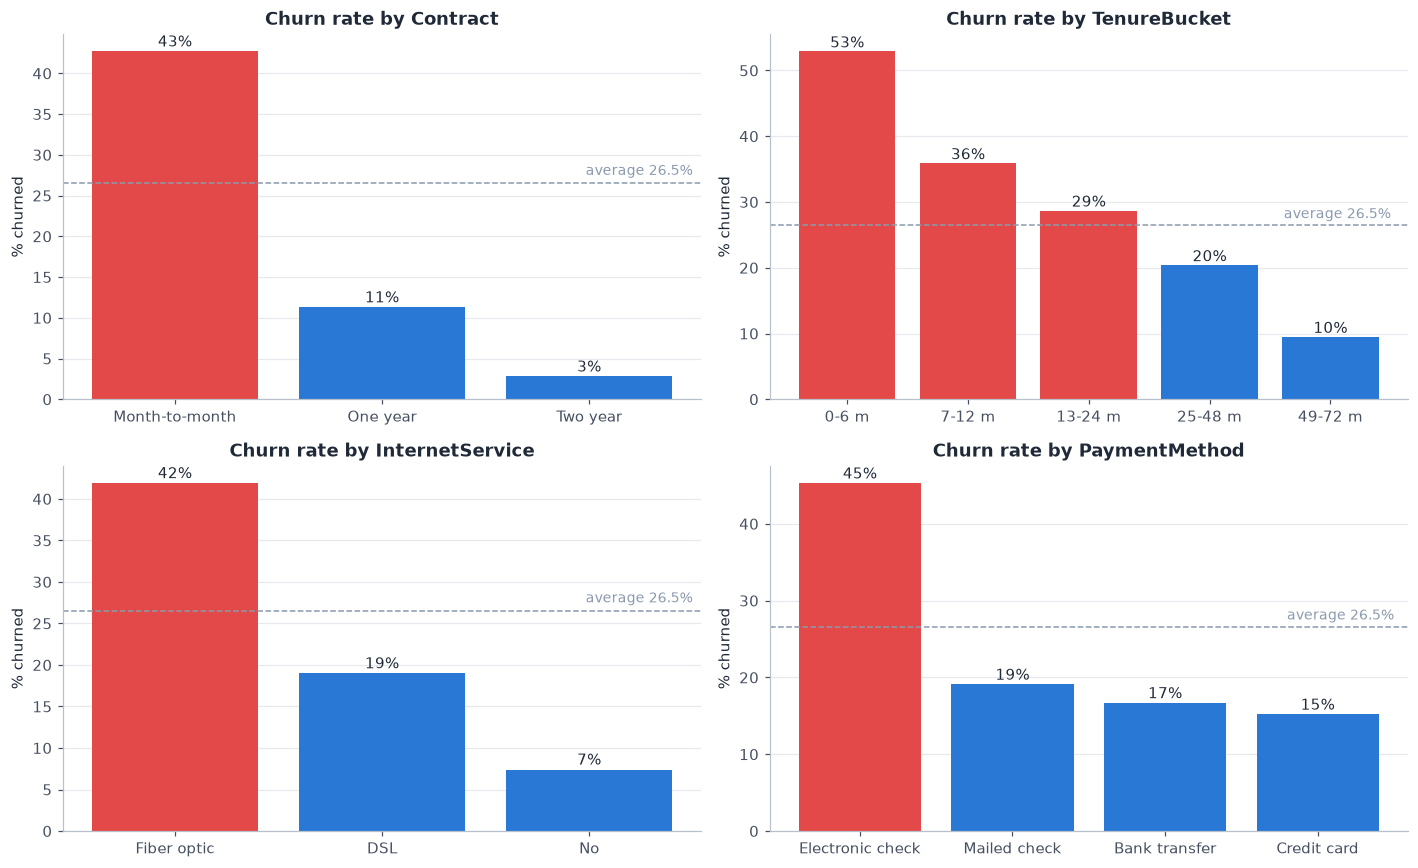

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 8))
order = {'Contract': ['Month-to-month', 'One year', 'Two year'], 'TenureBucket': ['0-6 m', '7-12 m', '13-24 m', '25-48 m', '49-72 m'],
         'InternetService': ['Fiber optic', 'DSL', 'No'], 'PaymentMethod': ['Electronic check', 'Mailed check', 'Bank transfer', 'Credit card']}
avg = df.ChurnFlag.mean() * 100
for a, (c, o) in zip(ax.ravel(), order.items()):
    t = churn_by(c, o)
    bars = a.bar(t.index.astype(str), t['churn_rate'], color=[RED if v > avg else BLUE for v in t['churn_rate']])
    a.axhline(avg, color=GREY, ls='--', lw=1); a.text(len(t) - .5, avg + 1, f'average {avg:.1f}%', ha='right', color=GREY, fontsize=9)
    for b, v in zip(bars, t['churn_rate']): a.text(b.get_x() + b.get_width() / 2, v + .6, f'{v:.0f}%', ha='center', fontsize=10)
    a.set_title(f'Churn rate by {c}'); a.set_ylabel('% churned'); a.grid(axis='x', visible=False)
plt.tight_layout(); save('01_churn_by_segment')

## 4. Tenure and price: when do customers leave, and does price matter?

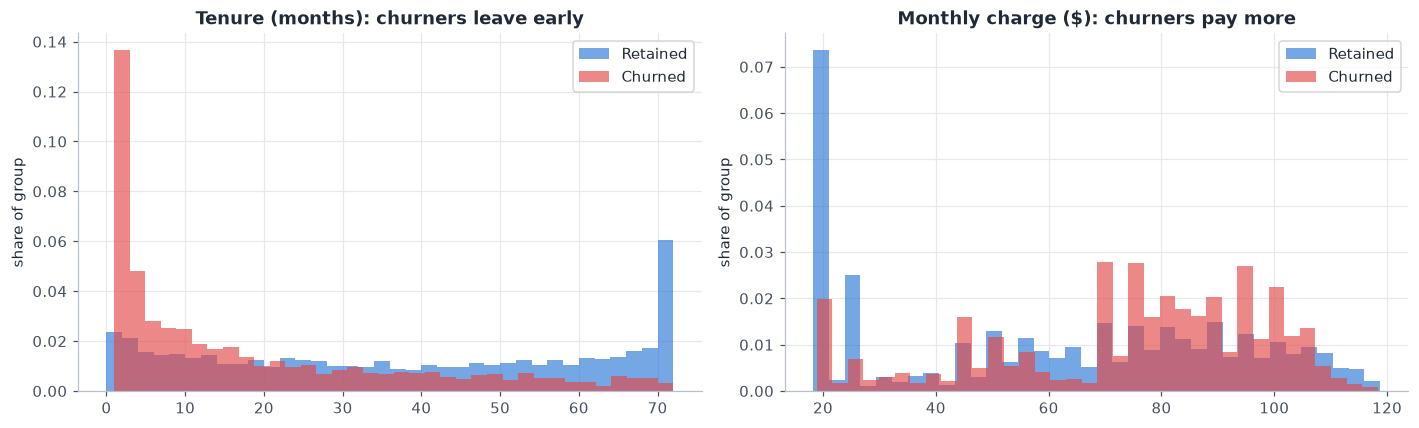

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for flag, col, lab in [(0, BLUE, 'Retained'), (1, RED, 'Churned')]:
    ax[0].hist(df[df.ChurnFlag == flag].tenure, bins=36, alpha=.65, color=col, label=lab, density=True)
    ax[1].hist(df[df.ChurnFlag == flag].MonthlyCharges, bins=36, alpha=.65, color=col, label=lab, density=True)
ax[0].set_title('Tenure (months): churners leave early'); ax[1].set_title('Monthly charge ($): churners pay more')
for a in ax: a.legend(); a.set_ylabel('share of group')
plt.tight_layout(); save('02_tenure_price_distribution')

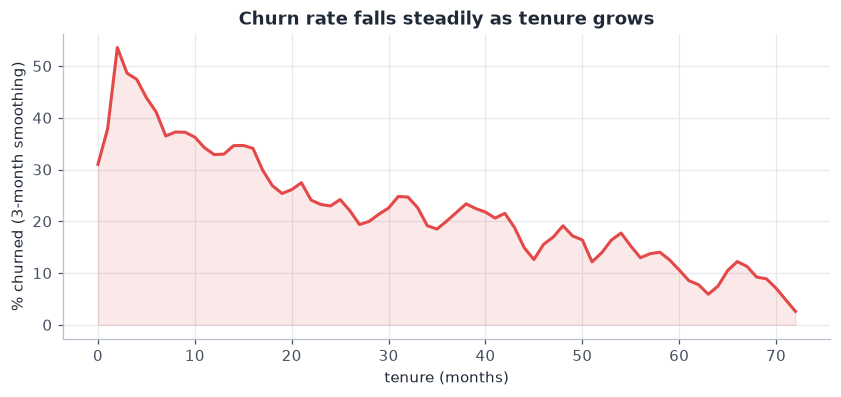

In [10]:
# Survival-style view: share of each tenure cohort that has churned
s = df.groupby('tenure').ChurnFlag.mean().rolling(3, center=True, min_periods=1).mean() * 100
plt.figure(figsize=(9, 3.6)); plt.plot(s.index, s.values, color=RED, lw=2)
plt.fill_between(s.index, s.values, color=RED, alpha=.12); plt.xlabel('tenure (months)'); plt.ylabel('% churned (3-month smoothing)')
plt.title('Churn rate falls steadily as tenure grows'); save('03_churn_by_tenure')

## 5. Are these differences real? Statistical tests
With 7,043 customers even small gaps can be significant, so we also report **effect size** (Cramér's V for categories; 0.1 small, 0.3 medium, 0.5 large).

In [11]:
def cramers_v(col):
    ct = pd.crosstab(df[col], df.ChurnFlag); chi2, p, dof, _ = stats.chi2_contingency(ct)
    return pd.Series({'chi2': chi2, 'p_value': p, 'cramers_v': np.sqrt(chi2 / (len(df) * (min(ct.shape) - 1)))})
cats = ['Contract', 'InternetService', 'PaymentMethod', 'OnlineSecurity', 'TechSupport', 'OnlineBackup', 'DeviceProtection',
        'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'SeniorCitizen', 'Partner', 'Dependents', 'MultipleLines', 'PhoneService', 'gender']
cv = pd.DataFrame({c: cramers_v(c) for c in cats}).T.sort_values('cramers_v', ascending=False)
cv['significant (p<0.05)'] = cv.p_value < .05
cv.assign(p_value=cv.p_value.map(lambda x: f'{x:.1e}'), chi2=cv.chi2.round(1), cramers_v=cv.cramers_v.round(3)).to_csv(TABLES / 'association_tests.csv')
cv.round(4)

,chi2,p_value,cramers_v,significant (p<0.05)
Contract,1184.5966,0.0000,0.4101,True
InternetService,732.3096,0.0000,0.3225,True
PaymentMethod,648.1423,0.0000,0.3034,True
PaperlessBilling,258.2776,0.0000,0.1915,True
OnlineSecurity,205.6331,0.0000,0.1709,True
TechSupport,190.1668,0.0000,0.1643,True
Dependents,189.1292,0.0000,0.1639,True
SeniorCitizen,159.4263,0.0000,0.1505,True
Partner,158.7334,0.0000,0.1501,True
OnlineBackup,47.2609,0.0000,0.0819,True


**Findings.** Contract (V = 0.41), internet service (0.32) and payment method (0.30) have medium-to-large associations with churn. Gender and phone service are not statistically significant (p > 0.3). Among numeric columns, **tenure has the largest effect** (rank-biserial 0.48): churners stay a median 10 months against 38.

In [12]:
# Numeric columns: Mann-Whitney U (no normality assumption) + rank-biserial effect size
rows = []
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    a, b = df[df.ChurnFlag == 1][c], df[df.ChurnFlag == 0][c]
    u, p = stats.mannwhitneyu(a, b); rb = 1 - 2 * u / (len(a) * len(b))
    rows.append({'feature': c, 'median_churned': a.median(), 'median_retained': b.median(), 'p_value': p, 'effect_size_rank_biserial': round(rb, 3)})
pd.DataFrame(rows).round(4)

,feature,median_churned,median_retained,p_value,effect_size_rank_biserial
0,tenure,10.00,38.000,0.0,0.480
1,MonthlyCharges,79.65,64.425,0.0,-0.242
2,TotalCharges,703.55,1679.525,0.0,0.301


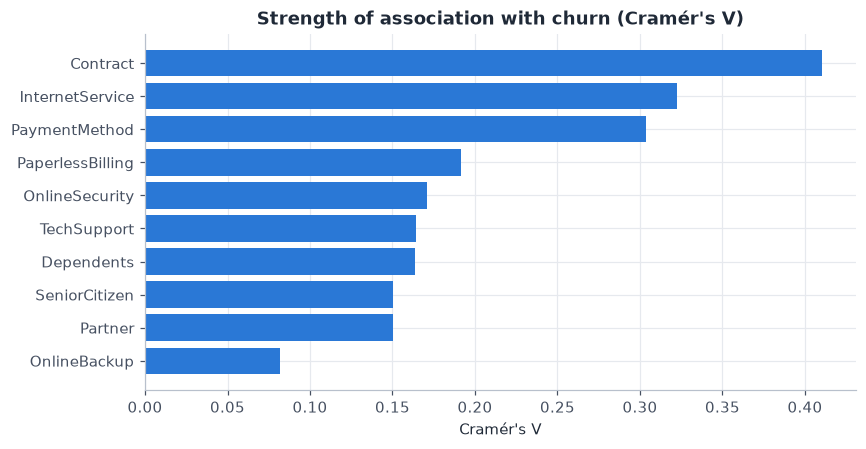

In [13]:
top = cv.head(10)
plt.figure(figsize=(8, 4.2)); plt.barh(top.index[::-1], top.cramers_v[::-1], color=BLUE)
plt.title("Strength of association with churn (Cramér's V)"); plt.xlabel("Cramér's V"); plt.tight_layout(); save('04_association_strength')

## 6. Combined effect: contract x tenure x internet service

TenureBucket,0-6 m,7-12 m,13-24 m,25-48 m,49-72 m
Contract,,,,,
Month-to-month,55.2,42.0,37.7,32.9,26.0
One year,10.3,10.6,8.1,10.6,12.9
Two year,0.0,0.0,0.0,2.2,3.3


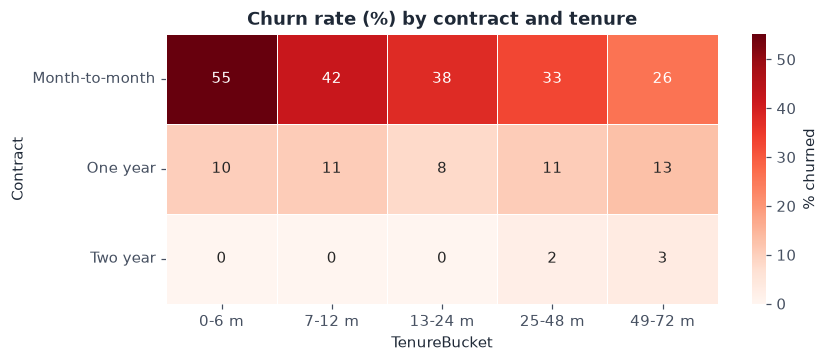

In [14]:
pivot = df.pivot_table(index='Contract', columns='TenureBucket', values='ChurnFlag', aggfunc='mean', observed=True) * 100
cnt = df.pivot_table(index='Contract', columns='TenureBucket', values='ChurnFlag', aggfunc='size', observed=True)
plt.figure(figsize=(8, 3.4)); sns.heatmap(pivot, annot=True, fmt='.0f', cmap='Reds', cbar_kws={'label': '% churned'}, linewidths=.5)
plt.title('Churn rate (%) by contract and tenure'); plt.tight_layout(); save('05_heatmap_contract_tenure')
pivot.round(1)

In [15]:
# The riskiest identifiable group: month-to-month, fiber optic, no tech support / security
risky = df[(df.Contract == 'Month-to-month') & (df.InternetService == 'Fiber optic') & (df.TechSupport == 'No') & (df.OnlineSecurity == 'No')]
print(f'Risky group: {len(risky):,} customers = {len(risky)/len(df):.0%} of base')
print(f'Churn rate: {risky.ChurnFlag.mean():.1%} vs {df.ChurnFlag.mean():.1%} overall')
print(f'Share of all churners: {risky.ChurnFlag.sum()/df.ChurnFlag.sum():.0%}')
print(f'MRR lost in this group: ${risky[risky.ChurnFlag==1].MonthlyCharges.sum():,.0f} of ${df[df.ChurnFlag==1].MonthlyCharges.sum():,.0f}')

Risky group: 1,524 customers = 22% of base
Churn rate: 60.7% vs 26.5% overall
Share of all churners: 49%
MRR lost in this group: $78,366 of $139,131


**Finding.** One in five customers (22%) is on a month-to-month fiber plan with no security or tech support. They churn at **60.7%** and account for **49% of all churners** and $78k of the $139k monthly revenue lost. This is the first group a retention programme should target.

## 7. Revenue at risk by segment

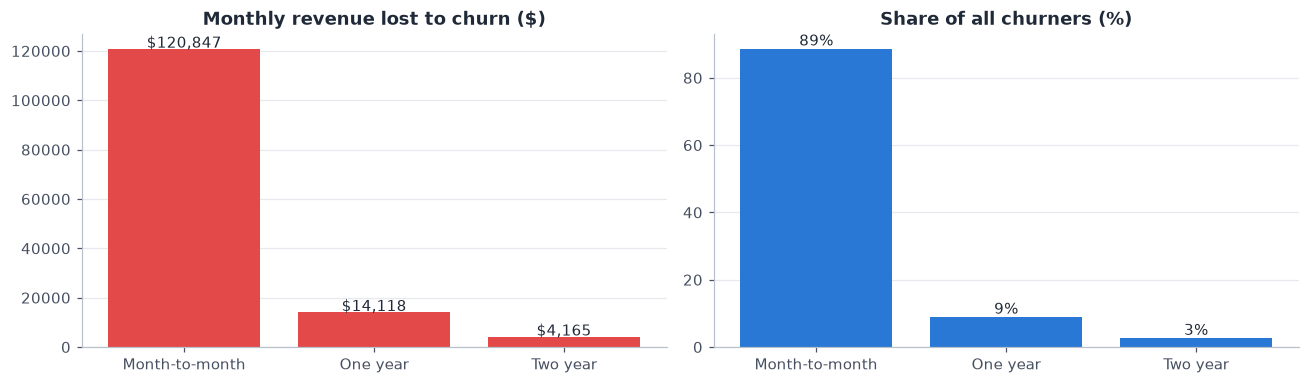

In [16]:
seg = churn_by('Contract', ['Month-to-month', 'One year', 'Two year'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(seg.index, seg.mrr_lost, color=RED); ax[0].set_title('Monthly revenue lost to churn ($)')
for i, v in enumerate(seg.mrr_lost): ax[0].text(i, v + 500, f'${v:,.0f}', ha='center')
ax[1].bar(seg.index, seg['share_of_all_churners_%'], color=BLUE); ax[1].set_title('Share of all churners (%)')
for i, v in enumerate(seg['share_of_all_churners_%']): ax[1].text(i, v + 1, f'{v:.0f}%', ha='center')
for a in ax: a.grid(axis='x', visible=False)
plt.tight_layout(); save('06_revenue_at_risk_by_contract')